# Philadelphia Shooting Victims, 2015–2026

**Coco Zhou**  
MUSA 5500 — Data Visualization Assignment 2

This notebook explores the Philadelphia shooting-victim dataset. I focus on three simple questions:

1. How did the number of shooting victims change across complete years?
2. Does victim age differ between fatal and non-fatal shootings?
3. When do shootings occur, and how do the patterns vary by police district?

The data is a City of Philadelphia shooting-victim export. Each row represents one shooting victim and includes the incident date and time, police district, victim characteristics, wound location, and whether the shooting was fatal.

## 1. Import packages and load the data

In [10]:
from pathlib import Path

import altair as alt
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
alt.data_transformers.disable_max_rows()

# One Cubehelix family keeps every chart visually consistent.
shooting_colors = sns.cubehelix_palette(
    n_colors=6, start=0, rot=0.4, gamma=1.0, hue=0.8, light=0.85, dark=0.15, reverse=False, as_cmap=False
)
shooting_hex = shooting_colors.as_hex()
shooting_cmap = sns.cubehelix_palette(
    start=0, rot=0.4, gamma=1.0, hue=0.8, light=0.85, dark=0.15, reverse=False, as_cmap=True
)

# This is the path to the data folder on my computer.
data_path = Path(r'C:\Upenn\python\Assignment 2\data') / 'shootings.csv'

# These fallbacks let the notebook run if the notebook and CSV are moved together.
if not data_path.exists():
    data_path = Path('data') / 'shootings.csv'
if not data_path.exists():
    data_path = Path('source_files') / 'shootings.csv'

shootings = pd.read_csv(data_path)
shootings.head()

,the_geom,the_geom_webmercator,year,dist,dc_key,code,date_,time,race,sex,...,officer_involved,offender_injured,offender_deceased,location,point_x,point_y,gdb_geomattr_data,objectid,lat,lng
0,0101000020E610000018A3F6D48AC452C0B02428D4CC05...,0101000020110F0000B377ACA3FFE05FC1A89F14525496...,2015,2.0,2.015020e+11,400.0,2015-05-25,03:30:00,W,M,...,N,N,N,1500 BLOCK Longshore Ave,-75.070974,40.045313,NaN,1,40.045313,-75.070974
1,0101000020E61000000CBADA43C8C552C0687D0B042405...,0101000020110F00007413DFD41AE35FC1AB60190B9995...,2015,2.0,2.015020e+11,400.0,2015-05-29,17:30:00,B,M,...,N,N,N,6100 BLOCK Algon Ave,-75.090348,40.040162,NaN,2,40.040162,-75.090348
2,0101000020E610000064A4FCA9F3C552C0C0912E0DEE03...,0101000020110F000000A68C8C64E35FC1882578364194...,2015,2.0,2.015021e+11,3400.0,2015-09-20,06:16:00,B,M,...,N,N,N,900 BLOCK Pratt St,-75.092997,40.030702,NaN,3,40.030702,-75.092997
3,0101000020E610000064A4FCA9F3C552C0C0912E0DEE03...,0101000020110F000000A68C8C64E35FC1882578364194...,2015,2.0,2.015021e+11,3400.0,2015-09-20,06:16:00,B,M,...,N,N,N,900 BLOCK Pratt St,-75.092997,40.030702,NaN,4,40.030702,-75.092997
4,0101000020E610000064A4FCA9F3C552C0C0912E0DEE03...,0101000020110F000000A68C8C64E35FC1882578364194...,2015,2.0,2.015021e+11,3400.0,2015-09-20,06:16:00,B,M,...,N,N,N,900 BLOCK Pratt St,-75.092997,40.030702,NaN,5,40.030702,-75.092997


I start by checking the size, time coverage, and missing values in the fields used below. The file includes records through 2026, but 2026 is incomplete, so I use 2015–2025 for charts that compare full years.

In [11]:
print(f'Rows: {shootings.shape[0]:,}')
print(f'Columns: {shootings.shape[1]}')
print(f'Years in the file: {shootings["year"].min()}–{shootings["year"].max()}')

shootings[['year', 'date_', 'time', 'dist', 'race', 'sex', 'age', 'fatal']].isna().sum()

Rows: 17,960
Columns: 26
Years in the file: 2015–2026


year       0
date_      0
time     174
dist       2
race     174
sex       26
age      304
fatal    174
dtype: int64

## 2. Clean the fields used for visualization

In [12]:
# Convert the date and time fields to a format that is easier to group.
shootings['date_'] = pd.to_datetime(shootings['date_'], errors='coerce')
shootings['hour'] = pd.to_datetime(
    shootings['time'], format='%H:%M:%S', errors='coerce'
).dt.hour
shootings['fatal_label'] = shootings['fatal'].map({0: 'Non-fatal', 1: 'Fatal'})
shootings['district_label'] = shootings['dist'].apply(
    lambda x: f'District {int(x)}' if pd.notna(x) else 'Unknown district'
)

# A clean subset for comparisons across complete calendar years.
complete_years = shootings[shootings['year'].between(2015, 2025)].copy()
complete_years[['date_', 'hour', 'fatal_label', 'district_label']].head()

,date_,hour,fatal_label,district_label
0,2015-05-25,3.0,Non-fatal,District 2
1,2015-05-29,17.0,Non-fatal,District 2
2,2015-09-20,6.0,Non-fatal,District 2
3,2015-09-20,6.0,Non-fatal,District 2
4,2015-09-20,6.0,Non-fatal,District 2


## 3. Matplotlib chart: shooting victims by year

### Why Matplotlib?

I chose Matplotlib for this time-series chart because I wanted direct control over the line, point labels, grid, and annotation. A single yearly trend is easiest to read as a clean line chart, and Matplotlib makes those small styling choices straightforward.

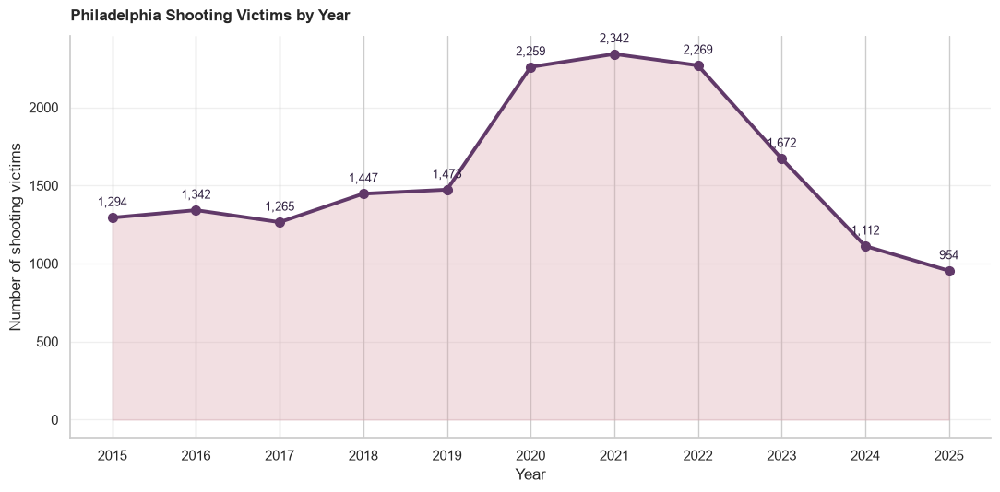

In [13]:
yearly_counts = complete_years.groupby('year').size().reset_index(name='victim_count')

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(
    yearly_counts['year'], yearly_counts['victim_count'],
    color=shooting_hex[4], linewidth=2.8, marker='o', markersize=7
)
ax.fill_between(
    yearly_counts['year'], yearly_counts['victim_count'],
    color=shooting_hex[1], alpha=0.35
)

for row in yearly_counts.itertuples():
    ax.annotate(
        f'{row.victim_count:,}', (row.year, row.victim_count),
        xytext=(0, 9), textcoords='offset points', ha='center',
        fontsize=9, color=shooting_hex[5]
    )

ax.set_title('Philadelphia Shooting Victims by Year', loc='left', weight='bold', pad=12)
ax.set_xlabel('Year')
ax.set_ylabel('Number of shooting victims')
ax.set_xticks(yearly_counts['year'])
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Main conclusion:** The annual count rose sharply after 2019, reaching its highest level in 2021 (2,342 victims). Counts then declined each full year from 2022 through 2025, although 2025 remained below the pre-2020 baseline only in comparison with the earlier surge.

## 4. Seaborn chart: when shootings occur during the year

### Why Seaborn?

I chose a Seaborn heatmap because the data have two repeating time patterns at once: month of the year and hour of the day. A heatmap lets color show the number of victims in all 288 month-hour combinations without making the chart crowded. Seaborn is especially useful here because it makes a polished, readable heatmap with just a few styling choices.

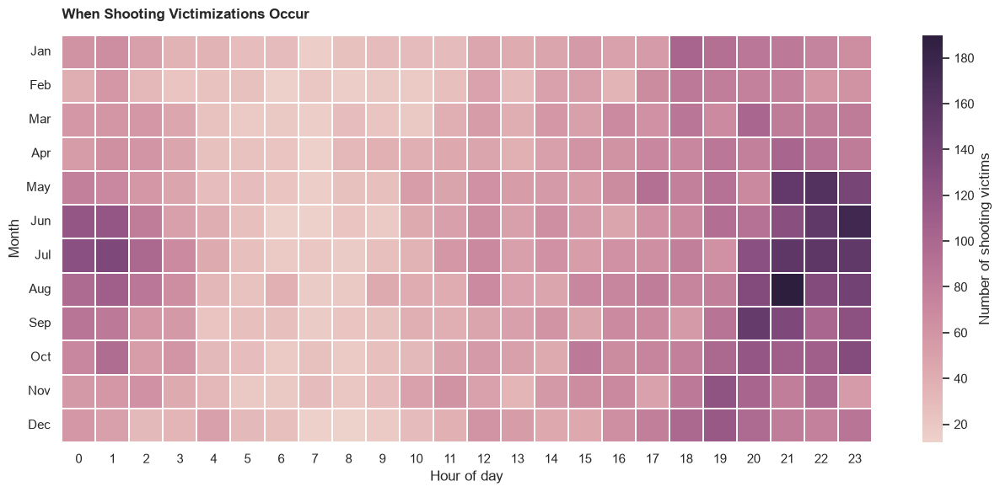

In [14]:
time_data = complete_years.dropna(subset=['hour']).copy()
time_data['month'] = time_data['date_'].dt.month

month_hour = pd.crosstab(time_data['month'], time_data['hour']).reindex(
    index=range(1, 13), columns=range(24), fill_value=0
)
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(
    month_hour, cmap=shooting_cmap, linewidths=0.25, linecolor='white',
    cbar_kws={'label': 'Number of shooting victims'}, ax=ax
)
ax.set_title('When Shooting Victimizations Occur', loc='left', weight='bold', pad=14)
ax.set_xlabel('Hour of day')
ax.set_ylabel('Month')
ax.set_yticklabels(month_labels, rotation=0)
ax.set_xticklabels([str(hour) for hour in range(24)], rotation=0)
plt.tight_layout()
plt.show()

**Main conclusion:** The highest concentrations occur in summer evenings. July at 9 p.m. is the single darkest month-hour combination, and the late-evening period from 7–11 p.m. is consistently darker than most other times of day.

## 5. Altair plot 1: shooting victims by hour

This chart uses an Altair **aggregate transformation**: `count()` turns the individual victim records into a total for each hour of the day. A line chart makes the repeated daily pattern easy to see.

In [15]:
hourly_chart = (
    alt.Chart(complete_years.dropna(subset=['hour']))
    .mark_line(point=True, color=shooting_hex[4], strokeWidth=3)
    .encode(
        x=alt.X('hour:Q', title='Hour of day', scale=alt.Scale(domain=[0, 23]), axis=alt.Axis(tickMinStep=1)),
        y=alt.Y('count():Q', title='Number of shooting victims'),
        tooltip=[
            alt.Tooltip('hour:Q', title='Hour'),
            alt.Tooltip('count():Q', title='Victims')
        ]
    )
    .properties(width=700, height=330, title='Shooting Victims by Hour of Day, 2015–2025')
)
hourly_chart

alt.Chart(...)

**Main conclusion:** Shooting victimizations are most common in the evening and late at night. The count rises after 5 p.m., peaks around 9–11 p.m., and then falls steadily during the early morning hours.

## 6. Altair plot 2: victim age distribution

This histogram uses two Altair transformations: **binning** puts ages into five-year ranges, and **counting** calculates how many victims are in each range. This is clearer than plotting every individual age.

In [16]:
age_data = complete_years[complete_years['age'].between(0, 90)].copy()

age_histogram = (
    alt.Chart(age_data)
    .mark_bar(color=shooting_hex[3], opacity=0.9)
    .encode(
        x=alt.X('age:Q', bin=alt.Bin(step=5), title='Victim age'),
        y=alt.Y('count():Q', title='Number of victims'),
        tooltip=[
            alt.Tooltip('age:Q', bin=alt.Bin(step=5), title='Age range'),
            alt.Tooltip('count():Q', title='Victims')
        ]
    )
    .properties(width=700, height=330, title='Distribution of Shooting Victim Ages, 2015–2025')
)
age_histogram

alt.Chart(...)

**Main conclusion:** The distribution is strongly concentrated among people in their late teens through early thirties. Counts decline after the 30–34 age group, although shooting victims appear across a much wider age range.

## 7. Altair plot 3: brush selection for age and time

This scatterplot uses a **brush selection**. Drag a rectangle over any part of the plot to highlight a group of victims by age and hour. The selection is useful for quickly examining combinations such as late-night incidents involving younger victims. I use a sample only to keep the interactive chart responsive.

In [17]:
brush = alt.selection_interval(name='age_hour_brush')
scatter_data = age_data.dropna(subset=['hour']).sample(
    n=min(5000, len(age_data)), random_state=42
)

age_hour_scatter = (
    alt.Chart(scatter_data)
    .mark_circle(size=38)
    .encode(
        x=alt.X('hour:Q', title='Hour of day', scale=alt.Scale(domain=[0, 23])),
        y=alt.Y('age:Q', title='Victim age', scale=alt.Scale(domain=[0, 90])),
        color=alt.Color('fatal_label:N', title='Outcome', scale=alt.Scale(
            domain=['Non-fatal', 'Fatal'], range=[shooting_hex[1], shooting_hex[5]]
        )),
        opacity=alt.condition(brush, alt.value(0.8), alt.value(0.12)),
        tooltip=[
            alt.Tooltip('age:Q', title='Age'),
            alt.Tooltip('hour:Q', title='Hour'),
            alt.Tooltip('fatal_label:N', title='Outcome'),
            alt.Tooltip('district_label:N', title='Police district')
        ]
    )
    .add_params(brush)
    .properties(width=700, height=380, title='Victim Age and Time of Shooting — Drag to Brush')
)
age_hour_scatter

alt.Chart(...)

**Main conclusion:** Victims aged roughly 18–35 appear at every hour of the day, but the densest concentration is in the evening and nighttime period. The brush makes it easier to isolate one time-and-age range without losing the surrounding context.

## 8. Extra credit: cross-filtered Altair dashboard

This dashboard links two Altair charts. Click a police-district bar on the left to filter the hourly pattern on the right; click again to clear the filter. The hourly chart uses `transform_filter()` so it updates from the selected district rather than showing a separate static chart.

In [18]:
dashboard_data = complete_years.dropna(subset=['dist', 'hour']).copy()
top_districts = dashboard_data['district_label'].value_counts().head(10).index.tolist()
dashboard_data = dashboard_data[dashboard_data['district_label'].isin(top_districts)]

district_select = alt.selection_point(fields=['district_label'], name='district_select')

district_bars = (
    alt.Chart(dashboard_data)
    .mark_bar()
    .encode(
        y=alt.Y('district_label:N', sort='-x', title='Police district'),
        x=alt.X('count():Q', title='Shooting victims'),
        color=alt.condition(district_select, alt.value(shooting_hex[5]), alt.value(shooting_hex[1])),
        tooltip=[alt.Tooltip('district_label:N', title='Police district'), alt.Tooltip('count():Q', title='Victims')]
    )
    .add_params(district_select)
    .properties(width=320, height=300, title='Click a District')
)

filtered_hours = (
    alt.Chart(dashboard_data)
    .transform_filter(district_select)
    .mark_line(point=True, color=shooting_hex[4], strokeWidth=3)
    .encode(
        x=alt.X('hour:Q', title='Hour of day', scale=alt.Scale(domain=[0, 23]), axis=alt.Axis(tickMinStep=1)),
        y=alt.Y('count():Q', title='Shooting victims'),
        tooltip=[alt.Tooltip('hour:Q', title='Hour'), alt.Tooltip('count():Q', title='Victims')]
    )
    .properties(width=420, height=300, title='Hourly Pattern for Selected District')
)

district_bars | filtered_hours

alt.HConcatChart(...)

**Main conclusion:** The dashboard shows that the ten districts with the most shooting victims do not necessarily have identical hourly patterns. Selecting one district makes it possible to compare its pattern with the citywide late-evening concentration.

## 9. Overall findings

The clearest pattern in this dataset is the sharp rise in shooting victims during 2020–2022, followed by lower counts in the next three complete years. Victims are concentrated among young adults, and incidents are concentrated in the evening and late-night hours. The interactive views help explore how those patterns vary by time, age, outcome, and police district.